In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv("/Users/mac/Desktop/Upwork/GoldSignalGenerator/Artifacts/gold.csv", skiprows=[1])

In [7]:
df.index = pd.to_datetime(df.index, utc=True).map(lambda x: x.tz_convert('Asia/Karachi'))
df = df.drop(df.index[0])
df = df.reset_index(drop=True)
df.rename(columns={"Price" : "Datetime"}, inplace=True)

In [8]:
df.head()

,Datetime,Close,High,Low,Open,Volume
0,2023-05-11 00:00:00,2037.099976,2038.599976,2036.199951,2038.599976,0.0
1,2023-05-11 01:00:00,2038.400024,2039.199951,2036.099976,2037.099976,2132.0
2,2023-05-11 02:00:00,2033.500000,2038.900024,2033.300049,2038.300049,6292.0
3,2023-05-11 03:00:00,2031.599976,2034.500000,2027.599976,2033.500000,10998.0
4,2023-05-11 04:00:00,2028.400024,2031.500000,2027.599976,2031.500000,7245.0


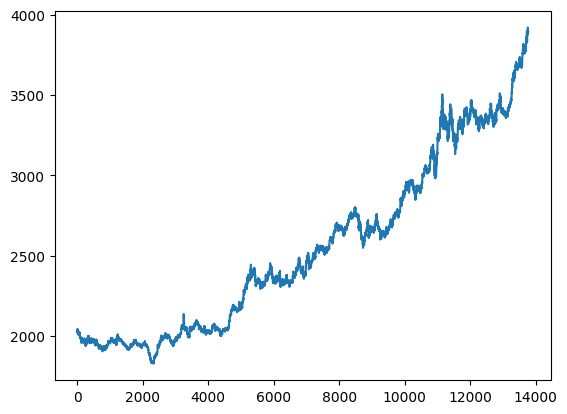

In [10]:
plt.plot(df.index, df["Close"])
plt.show()

In [11]:
print(df.head())

              Datetime        Close         High          Low         Open  \
0  2023-05-11 00:00:00  2037.099976  2038.599976  2036.199951  2038.599976   
1  2023-05-11 01:00:00  2038.400024  2039.199951  2036.099976  2037.099976   
2  2023-05-11 02:00:00  2033.500000  2038.900024  2033.300049  2038.300049   
3  2023-05-11 03:00:00  2031.599976  2034.500000  2027.599976  2033.500000   
4  2023-05-11 04:00:00  2028.400024  2031.500000  2027.599976  2031.500000   

    Volume  
0      0.0  
1   2132.0  
2   6292.0  
3  10998.0  
4   7245.0  


In [12]:
from ta.momentum import RSIIndicator
from ta.trend import EMAIndicator, MACD
from ta.volatility import AverageTrueRange

df['Datetime'] = pd.to_datetime(df['Datetime'])
df = df.sort_values('Datetime')

df['return'] = df['Close'].pct_change()

df['ema_fast'] = EMAIndicator(df['Close'], window=12).ema_indicator()
df['ema_slow'] = EMAIndicator(df['Close'], window=26).ema_indicator()

df['rsi'] = RSIIndicator(df['Close'], window=14).rsi()

macd = MACD(df['Close'])
df['macd'] = macd.macd()
df['macd_signal'] = macd.macd_signal()

df['ATR'] = AverageTrueRange(df['High'], df['Low'], df['Close'], window=14).average_true_range()

In [13]:
horizon = 6  
threshold = 0.003

df['future_return'] = (df['Close'].shift(-horizon) - df['Close']) / df['Close']

def label_signal(x):
    if x > threshold:
        return 1   # Buy
    elif x < -threshold:
        return 2   # Sell
    else:
        return 0   # Hold

df['signal'] = df['future_return'].apply(label_signal)


In [14]:
rr_ratio = 2   # Reward:Risk = 2:1
risk_mult = 1  # Stop loss = 1 * ATR

df['Entry'] = df['Close']

df['StopLoss'] = np.where(
    df['signal'] == 1, df['Entry'] - risk_mult * df['ATR'],  # Buy → SL below
    np.where(df['signal'] == 2, df['Entry'] + risk_mult * df['ATR'], np.nan)  # Sell → SL above
)

df['TakeProfit'] = np.where(
    df['signal'] == 1, df['Entry'] + rr_ratio * risk_mult * df['ATR'],  # Buy → TP above
    np.where(df['signal'] == 2, df['Entry'] - rr_ratio * risk_mult * df['ATR'], np.nan)  # Sell → TP below
)


In [15]:
df.head()

,Datetime,Close,High,Low,Open,Volume,return,ema_fast,ema_slow,rsi,macd,macd_signal,ATR,future_return,signal,Entry,StopLoss,TakeProfit
0,2023-05-11 00:00:00,2037.099976,2038.599976,2036.199951,2038.599976,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,-0.001031,0,2037.099976,NaN,NaN
1,2023-05-11 01:00:00,2038.400024,2039.199951,2036.099976,2037.099976,2132.0,0.000638,NaN,NaN,NaN,NaN,NaN,0.0,0.002257,0,2038.400024,NaN,NaN
2,2023-05-11 02:00:00,2033.500000,2038.900024,2033.300049,2038.300049,6292.0,-0.002404,NaN,NaN,NaN,NaN,NaN,0.0,0.004918,1,2033.500000,2033.500000,2033.500000
3,2023-05-11 03:00:00,2031.599976,2034.500000,2027.599976,2033.500000,10998.0,-0.000934,NaN,NaN,NaN,NaN,NaN,0.0,-0.006497,2,2031.599976,2031.599976,2031.599976
4,2023-05-11 04:00:00,2028.400024,2031.500000,2027.599976,2031.500000,7245.0,-0.001575,NaN,NaN,NaN,NaN,NaN,0.0,-0.000690,0,2028.400024,NaN,NaN


In [16]:
df.tail()

,Datetime,Close,High,Low,Open,Volume,return,ema_fast,ema_slow,rsi,macd,macd_signal,ATR,future_return,signal,Entry,StopLoss,TakeProfit
13762,2025-10-01 12:00:00,3897.600098,3898.199951,3887.300049,3895.000000,10920.0,0.000642,3899.620940,3891.866059,54.173057,7.754881,9.918989,14.186480,NaN,0,3897.600098,NaN,NaN
13763,2025-10-01 13:00:00,3887.399902,3898.500000,3887.300049,3897.699951,9975.0,-0.002617,3897.740781,3891.535233,47.791290,6.205548,9.176301,13.973156,NaN,0,3887.399902,NaN,NaN
13764,2025-10-01 14:00:00,3888.699951,3893.100098,3881.399902,3887.600098,11591.0,0.000334,3896.349884,3891.325212,48.622040,5.024672,8.345975,13.810802,NaN,0,3888.699951,NaN,NaN
13765,2025-10-01 15:00:00,3894.300049,3897.600098,3887.800049,3888.800049,7184.0,0.001440,3896.034525,3891.545570,52.153832,4.488954,7.574571,13.524320,NaN,0,3894.300049,NaN,NaN
13766,2025-10-01 16:00:00,3894.300049,3894.399902,3893.199951,3894.300049,152.0,0.000000,3895.767682,3891.749606,52.153832,4.018076,6.863272,12.644008,NaN,0,3894.300049,NaN,NaN


In [17]:
df['signal'].value_counts(normalize=True) * 100


signal
0    59.461030
1    22.503087
2    18.035883
Name: proportion, dtype: float64

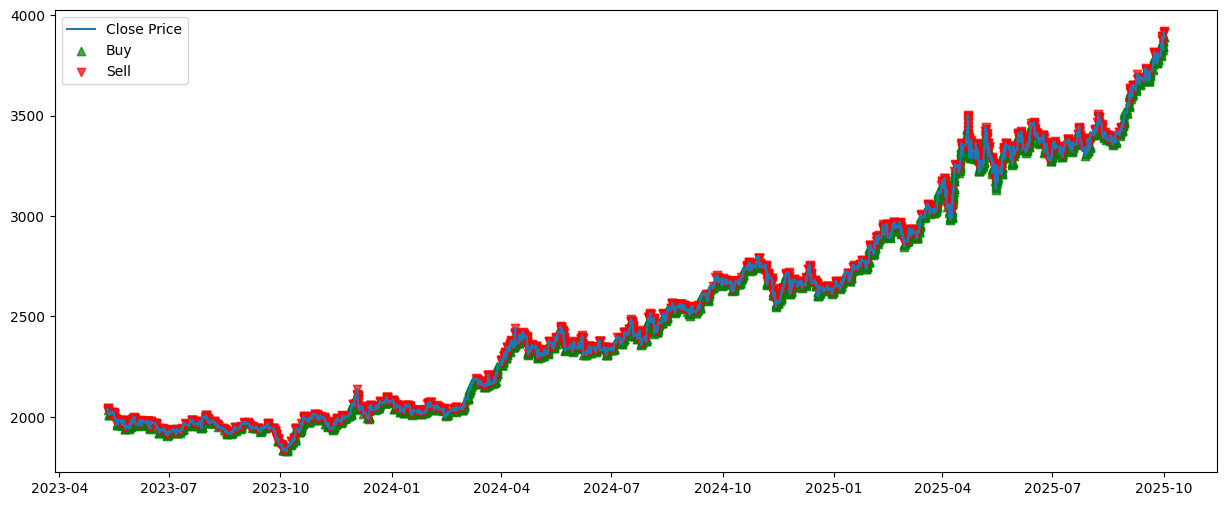

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,6))
plt.plot(df['Datetime'], df['Close'], label='Close Price')

buy_signals = df[df['signal'] == 1]
sell_signals = df[df['signal'] == 2]

plt.scatter(buy_signals['Datetime'], buy_signals['Close'], marker='^', color='green', label='Buy', alpha=0.7)
plt.scatter(sell_signals['Datetime'], sell_signals['Close'], marker='v', color='red', label='Sell', alpha=0.7)

plt.legend()
plt.show()


In [22]:
def check_trade(row):
    if row['signal'] == 1:  # Buy
        if row['TakeProfit'] <= df.loc[row.name+6, 'High']:  # hit TP within horizon
            return 1
        elif row['StopLoss'] >= df.loc[row.name+6, 'Low']:  # hit SL
            return -1
    elif row['signal'] == 2:  # Sell
        if row['TakeProfit'] >= df.loc[row.name+6, 'Low']:
            return 1
        elif row['StopLoss'] <= df.loc[row.name+6, 'High']:
            return -1
    return 0

df['trade_result'] = df.apply(check_trade, axis=1)

In [23]:
(df['trade_result'] == 1).mean() * 100  # Win rate %

np.float64(23.948572673785137)

<Axes: xlabel='Datetime'>

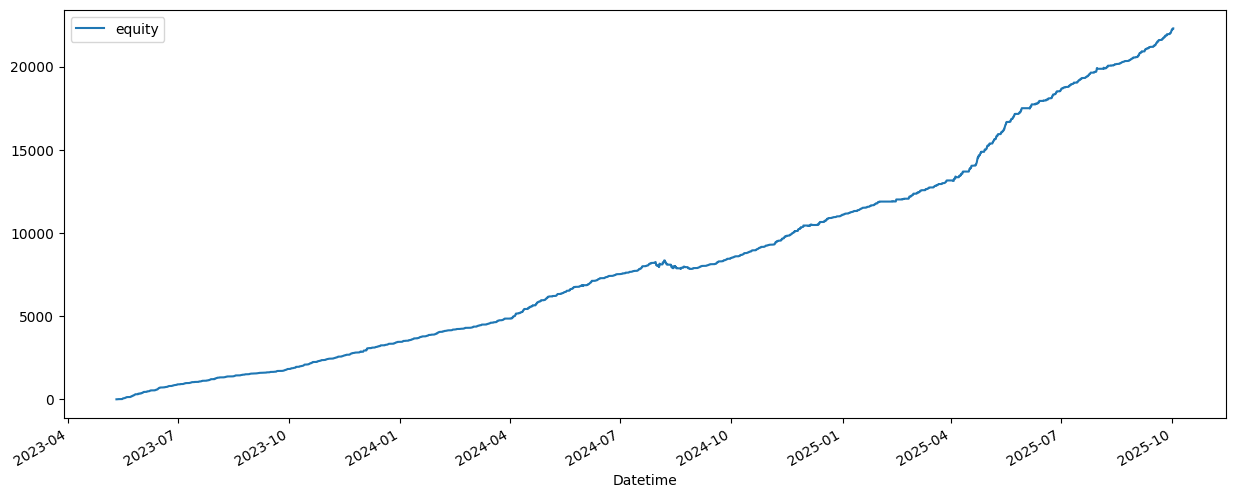

In [24]:
df['pnl'] = df['trade_result'] * df['ATR']  # rough profit per trade
df['equity'] = df['pnl'].cumsum()

df[['Datetime','equity']].set_index('Datetime').plot(figsize=(15,6))

In [25]:
wins = df[df['trade_result'] == 1]['pnl']
losses = df[df['trade_result'] == -1]['pnl']
print("Avg Win:", wins.mean())
print("Avg Loss:", losses.mean())

Avg Win: 7.265638575674123
Avg Loss: -20.365341549404647


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ta.volatility import AverageTrueRange

def backtest_strategy(df, horizon=6, threshold=0.003, rr_ratio=2, risk_mult=1):
    df = df.copy()
    df = df.sort_values("Datetime").reset_index(drop=True)
    
    # ATR for SL/TP calculation
    df['ATR'] = AverageTrueRange(
        df['High'], df['Low'], df['Close'], window=14
    ).average_true_range()
    
    # Future returns
    df['future_return'] = (df['Close'].shift(-horizon) - df['Close']) / df['Close']
    
    # Label signals
    def label_signal(x):
        if x > threshold:
            return 1   # Buy
        elif x < -threshold:
            return 2   # Sell
        else:
            return 0   # Hold
    df['signal'] = df['future_return'].apply(label_signal)
    
    # Entry, SL, TP
    df['Entry'] = df['Close']
    df['StopLoss'] = np.where(
        df['signal'] == 1, df['Entry'] - risk_mult * df['ATR'],
        np.where(df['signal'] == 2, df['Entry'] + risk_mult * df['ATR'], np.nan)
    )
    df['TakeProfit'] = np.where(
        df['signal'] == 1, df['Entry'] + rr_ratio * risk_mult * df['ATR'],
        np.where(df['signal'] == 2, df['Entry'] - rr_ratio * risk_mult * df['ATR'], np.nan)
    )
    
    # Backtest results
    results = []
    for i in range(len(df) - horizon):
        row = df.iloc[i]
        if row['signal'] == 0:
            results.append(0)
            continue
        
        future_slice = df.iloc[i+1:i+horizon+1]
        
        if row['signal'] == 1:  # Buy
            hit_tp = (future_slice['High'] >= row['TakeProfit']).any()
            hit_sl = (future_slice['Low'] <= row['StopLoss']).any()
            if hit_tp and not hit_sl:
                results.append(1)
            elif hit_sl and not hit_tp:
                results.append(-1)
            elif hit_tp and hit_sl:  # both triggered, pick whichever happened first
                tp_time = future_slice[future_slice['High'] >= row['TakeProfit']].index[0]
                sl_time = future_slice[future_slice['Low'] <= row['StopLoss']].index[0]
                results.append(1 if tp_time < sl_time else -1)
            else:
                results.append(0)

        elif row['signal'] == 2:  # Sell
            hit_tp = (future_slice['Low'] <= row['TakeProfit']).any()
            hit_sl = (future_slice['High'] >= row['StopLoss']).any()
            if hit_tp and not hit_sl:
                results.append(1)
            elif hit_sl and not hit_tp:
                results.append(-1)
            elif hit_tp and hit_sl:
                tp_time = future_slice[future_slice['Low'] <= row['TakeProfit']].index[0]
                sl_time = future_slice[future_slice['High'] >= row['StopLoss']].index[0]
                results.append(1 if tp_time < sl_time else -1)
            else:
                results.append(0)
    
    df['trade_result'] = results + [0]*(len(df)-len(results))
    df['pnl'] = df['trade_result'] * df['ATR']  # simple PnL = ±ATR
    df['equity'] = df['pnl'].cumsum()
    
    # ---- Summary Stats ----
    total_trades = (df['signal'] != 0).sum()
    wins = (df['trade_result'] == 1).sum()
    losses = (df['trade_result'] == -1).sum()
    win_rate = wins / (wins + losses + 1e-9) * 100
    
    avg_win = df.loc[df['trade_result'] == 1, 'pnl'].mean()
    avg_loss = abs(df.loc[df['trade_result'] == -1, 'pnl'].mean())
    profit_factor = (wins * avg_win) / (losses * avg_loss + 1e-9)
    
    print("📊 Strategy Report")
    print(f"Total Trades: {total_trades}")
    print(f"Win Rate: {win_rate:.2f}%")
    print(f"Profit Factor: {profit_factor:.2f}")
    print(f"Avg Win: {avg_win:.2f}, Avg Loss: {avg_loss:.2f}")
    
    return df


In [32]:
results_df = backtest_strategy(df, horizon=6, threshold=0.003, rr_ratio=2)

📊 Strategy Report
Total Trades: 5581
Win Rate: 75.34%
Profit Factor: 2.05
Avg Win: 8.00, Avg Loss: 11.91


In [35]:
import itertools

def optimize_strategy(df, horizons=[6, 12, 24], thresholds=[0.003, 0.005, 0.01], rr_ratios=[2, 3]):
    results = []
    for h, t, rr in itertools.product(horizons, thresholds, rr_ratios):
        print(f"Testing Horizon={h}, Threshold={t}, RR={rr}...")
        res = backtest_strategy(df, horizon=h, threshold=t, rr_ratio=rr)
        report = {
            "horizon": h,
            "threshold": t,
            "rr_ratio": rr,
            "total_trades": len(res),
            "win_rate": (res['pnl'] > 0).mean() * 100,
            "profit_factor": res[res['pnl'] > 0]['pnl'].sum() / abs(res[res['pnl'] < 0]['pnl'].sum())
        }
        results.append(report)
    
    results_df = pd.DataFrame(results)
    print(results_df)
    return results_df.sort_values(by="profit_factor", ascending=False)


In [36]:
optimize_strategy(df)

Testing Horizon=6, Threshold=0.003, RR=2...
📊 Strategy Report
Total Trades: 5581
Win Rate: 75.34%
Profit Factor: 2.05
Avg Win: 8.00, Avg Loss: 11.91
Testing Horizon=6, Threshold=0.003, RR=3...
📊 Strategy Report
Total Trades: 5581
Win Rate: 61.53%
Profit Factor: 0.94
Avg Win: 6.96, Avg Loss: 11.84
Testing Horizon=6, Threshold=0.005, RR=2...
📊 Strategy Report
Total Trades: 2994
Win Rate: 79.04%
Profit Factor: 2.81
Avg Win: 8.86, Avg Loss: 11.90
Testing Horizon=6, Threshold=0.005, RR=3...
📊 Strategy Report
Total Trades: 2994
Win Rate: 71.57%
Profit Factor: 1.57
Avg Win: 7.41, Avg Loss: 11.87
Testing Horizon=6, Threshold=0.01, RR=2...
📊 Strategy Report
Total Trades: 748
Win Rate: 82.50%
Profit Factor: 4.54
Avg Win: 11.22, Avg Loss: 11.64
Testing Horizon=6, Threshold=0.01, RR=3...
📊 Strategy Report
Total Trades: 748
Win Rate: 80.26%
Profit Factor: 3.23
Avg Win: 9.25, Avg Loss: 11.64
Testing Horizon=12, Threshold=0.003, RR=2...
📊 Strategy Report
Total Trades: 7855
Win Rate: 66.55%
Profit Fac

,horizon,threshold,rr_ratio,total_trades,win_rate,profit_factor
4,6,0.010,2,13767,4.176654,4.542745
5,6,0.010,3,13767,3.602818,3.229243
2,6,0.005,2,13767,14.730878,2.809463
10,12,0.010,2,13767,9.341178,2.475441
0,6,0.003,2,13767,22.517615,2.052679
8,12,0.005,2,13767,24.384397,1.933584
11,12,0.010,3,13767,8.462265,1.928112
3,6,0.005,3,13767,9.885959,1.571254
6,12,0.003,2,13767,33.180795,1.564807
16,24,0.010,2,13767,17.200552,1.413738
